# Wasteland Pantry
### An ML System for Food Waste Prediction and Reduction

**Goal:** Predict how many kilograms of food will be wasted at a planned meal (college canteen / hostel mess), using information available *before* the meal.

**SDG link:** UN Sustainable Development Goal 12 (Responsible Consumption and Production).

> **Honest note:** The dataset is *synthetic* (computer-generated). So the results below show that the **method works as a prototype**. They do **not** prove it will reduce waste in a real canteen. That needs real data.



## 1. Setup and load data

Adding/Importing Libraries

In [27]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

sns.set_theme(style="whitegrid")
print("Libraries loaded")

Libraries loaded


**Importing Dataset** ,
also as pandas would't read "none" values as null so keep_default_na = false & na_values = [""]

In [28]:
df = pd.read_excel("Wasted.xlsx", keep_default_na=False, na_values=[""])
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (1800, 18)


,Record_id,Date,Week_day,Meal_Time,Menu_category,Event_type,Holiday_flag,Planned_Attendance_rate,Meals_planned,Expected_meals,Menu_Popularity_score,Portion_size(g),Forecast_temperature(C),forecast_rainfall(mm),Prior_similar_wasted_meal(kg),Actual_MealServed,Stockout_flag,Food_wasted(kg)
0,FW0001,2023-01-02,Monday,Lunch,North Indian,None,0,0.729,379,376,62.3,400,13.2,6.6,18.00,262,0,44.84
1,FW0002,2023-01-02,Monday,Breakfast,North Indian,None,0,0.813,182,182,73.5,300,15.5,0.1,7.00,156,0,8.81
2,FW0003,2023-01-02,Monday,Lunch,Snacks,College Event,0,0.862,531,511,69.8,300,23.6,5.6,24.71,472,0,23.26
3,FW0004,2023-01-04,Wednesday,Dinner,South Indian,None,0,0.811,321,319,76.0,350,22.7,0.3,14.00,263,0,19.38
4,FW0005,2023-01-05,Thursday,Dinner,South Indian,Festival,0,0.873,422,425,82.5,300,18.5,1.2,15.35,392,0,15.03


## 2. Check the data

Before building anything, we check the data quality like - types, missing values, duplicates and strange numbers.

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Record_id                      1800 non-null   object        
 1   Date                           1800 non-null   datetime64[ns]
 2   Week_day                       1800 non-null   object        
 3   Meal_Time                      1800 non-null   object        
 4   Menu_category                  1800 non-null   object        
 5   Event_type                     1800 non-null   object        
 6   Holiday_flag                   1800 non-null   int64         
 7   Planned_Attendance_rate        1800 non-null   float64       
 8   Meals_planned                  1800 non-null   int64         
 9   Expected_meals                 1800 non-null   int64         
 10  Menu_Popularity_score          1800 non-null   float64       
 11  Portion_size(g)  

In [30]:
# Missing values per column (if they have any)
missing = df.isna().sum()
print(missing[missing > 0])
print()
print("Duplicate rows:", df.duplicated().sum())
print("Record_id all unique:", df["Record_id"].is_unique)
print()
print(df["Event_type"].value_counts())

Forecast_temperature(C)    21
forecast_rainfall(mm)      27
dtype: int64

Duplicate rows: 0
Record_id all unique: True

Event_type
None             1401
College Event     141
Exam Period       119
Festival          102
Sports Event       37
Name: count, dtype: int64


In [32]:
#Summary of the numbers & also looking at min and max for anything odd
df.describe().round(2)

,Date,Holiday_flag,Planned_Attendance_rate,Meals_planned,Expected_meals,Menu_Popularity_score,Portion_size(g),Forecast_temperature(C),forecast_rainfall(mm),Prior_similar_wasted_meal(kg),Actual_MealServed,Stockout_flag,Food_wasted(kg)
count,1800,1800.00,1800.00,1800.00,1800.00,1800.00,1800.00,1779.00,1773.00,1800.00,1800.00,1800.00,1800.00
mean,2024-07-04 03:33:36,0.14,0.84,340.38,340.09,77.20,350.89,25.32,3.45,17.58,293.68,0.02,17.58
min,2023-01-02 00:00:00,0.00,0.49,104.00,99.00,49.40,250.00,8.00,0.00,5.08,57.00,0.00,0.58
25%,2023-10-04 06:00:00,0.00,0.77,241.00,242.75,71.20,300.00,20.00,0.60,13.46,192.00,0.00,11.17
50%,2024-07-06 00:00:00,0.00,0.84,344.00,344.00,77.40,350.00,25.40,1.70,18.06,284.50,0.00,16.56
75%,2025-04-07 06:00:00,0.00,0.91,428.25,428.25,83.00,400.00,30.80,4.40,21.46,383.00,0.00,22.96
max,2025-12-30 00:00:00,1.00,1.05,680.00,669.00,98.00,450.00,43.00,40.60,31.38,693.00,1.00,49.23
std,NaN,0.35,0.10,114.92,114.98,8.65,53.31,6.98,4.71,5.33,121.84,0.15,8.50


In [33]:
# Logic checks
print("Rows with attendance rate above 1:", (df["Planned_Attendance_rate"] > 1).sum())
print("Rows where meals served > meals planned:", (df["Actual_MealServed"] > df["Meals_planned"]).sum())
print("Rows with waste <= 0:", (df["Food_wasted(kg)"] <= 0).sum())
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())

Rows with attendance rate above 1: 90
Rows where meals served > meals planned: 152
Rows with waste <= 0: 0
Date range: 2023-01-02 to 2025-12-30


**What these does**
- Attendance above 1 (more than 100%) can happen in real life when extra people show up, so we keep these rows.
- Meals served above planned is also possible, so we keep them too.
- Missing temperature and rainfall values will be filled later using the **median** (the middle value).
- There are no duplicates and no impossible values (like negative waste).


## 3. Exploreing the data (EDA)

Charts help us see what is linked to food waste.

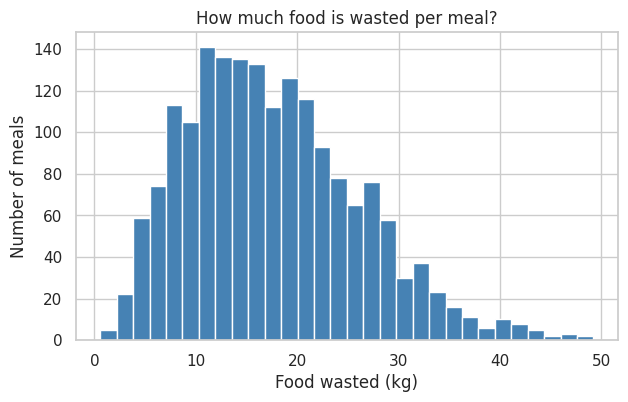

count    1800.00
mean       17.58
std         8.50
min         0.58
25%        11.17
50%        16.56
75%        22.96
max        49.23
Name: Food_wasted(kg), dtype: float64


In [34]:
plt.figure(figsize=(7,4))
plt.hist(df["Food_wasted(kg)"], bins=30, color="steelblue", edgecolor="white")
plt.title("How much food is wasted per meal?")
plt.xlabel("Food wasted (kg)")
plt.ylabel("Number of meals")
plt.show()
print(df["Food_wasted(kg)"].describe().round(2))

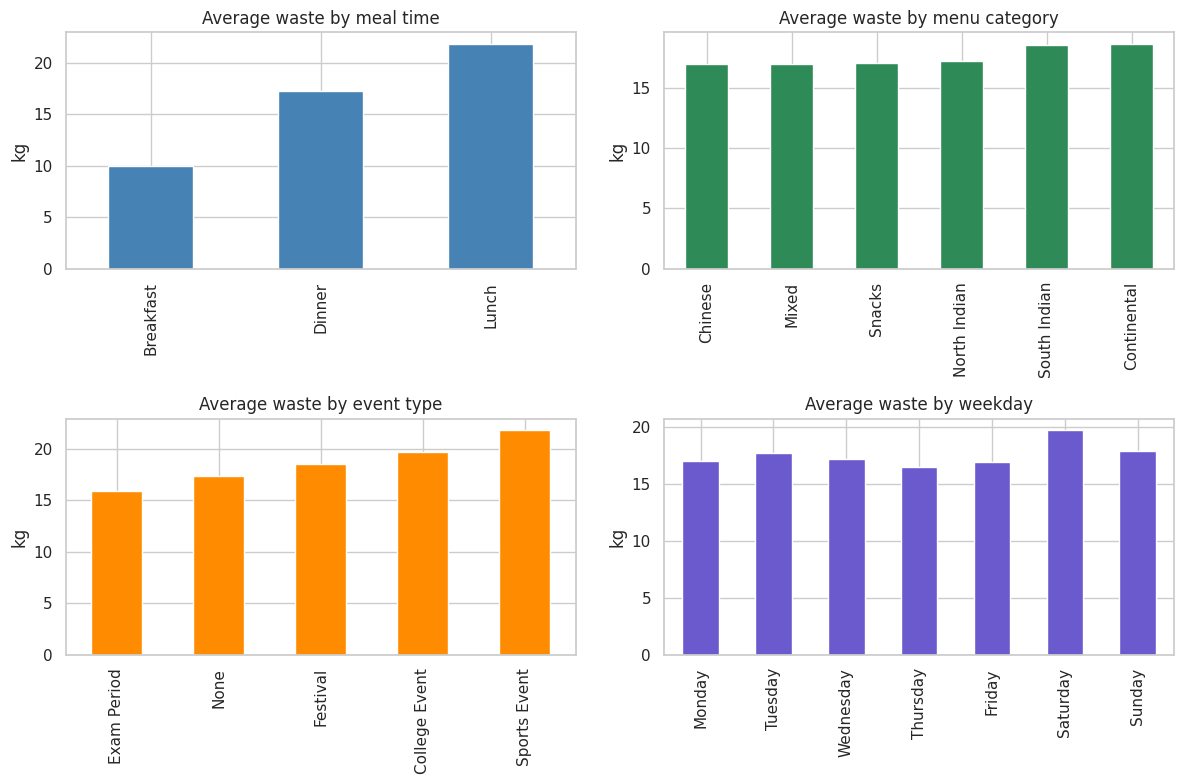

In [35]:
# Average waste by category
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
order_days = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

df.groupby("Meal_Time")["Food_wasted(kg)"].mean().plot(kind="bar", ax=axes[0,0], color="steelblue")
axes[0,0].set_title("Average waste by meal time")

df.groupby("Menu_category")["Food_wasted(kg)"].mean().sort_values().plot(kind="bar", ax=axes[0,1], color="seagreen")
axes[0,1].set_title("Average waste by menu category")

df.groupby("Event_type")["Food_wasted(kg)"].mean().sort_values().plot(kind="bar", ax=axes[1,0], color="darkorange")
axes[1,0].set_title("Average waste by event type")

df.groupby("Week_day")["Food_wasted(kg)"].mean().reindex(order_days).plot(kind="bar", ax=axes[1,1], color="slateblue")
axes[1,1].set_title("Average waste by weekday")

for ax in axes.flat:
    ax.set_xlabel("")
    ax.set_ylabel("kg")
plt.tight_layout()
plt.show()

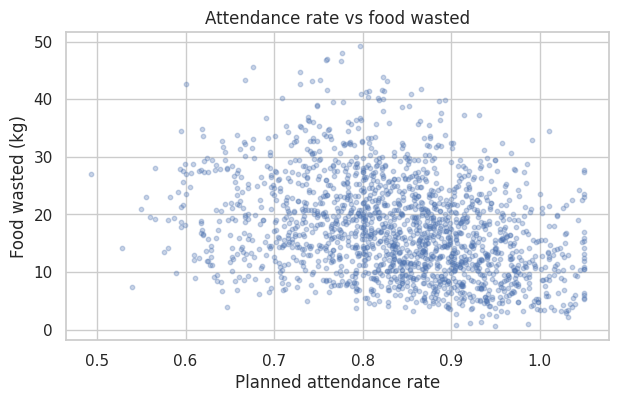

In [36]:
# Attendance and waste
plt.figure(figsize=(7,4))
plt.scatter(df["Planned_Attendance_rate"], df["Food_wasted(kg)"], alpha=0.3, s=10)
plt.title("Attendance rate vs food wasted")
plt.xlabel("Planned attendance rate")
plt.ylabel("Food wasted (kg)")
plt.show()

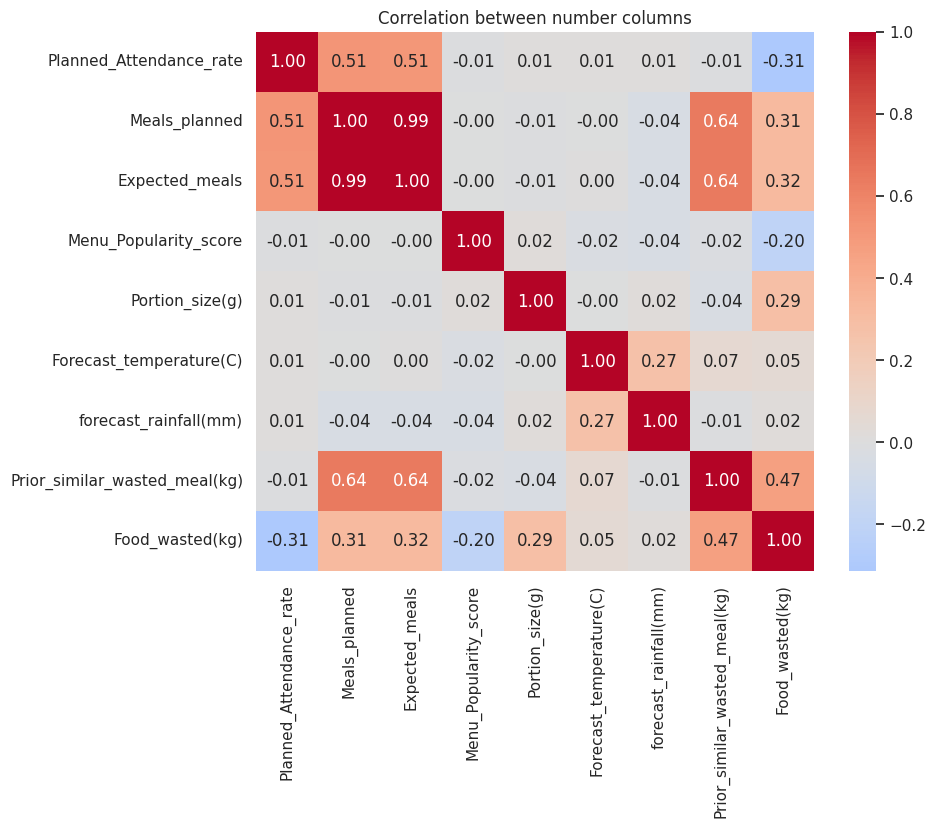

In [37]:
# Correlation heatmap of number columns
num_for_corr = ["Planned_Attendance_rate","Meals_planned","Expected_meals","Menu_Popularity_score",
                "Portion_size(g)","Forecast_temperature(C)","forecast_rainfall(mm)",
                "Prior_similar_wasted_meal(kg)","Food_wasted(kg)"]
plt.figure(figsize=(9,7))
sns.heatmap(df[num_for_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between number columns")
plt.show()

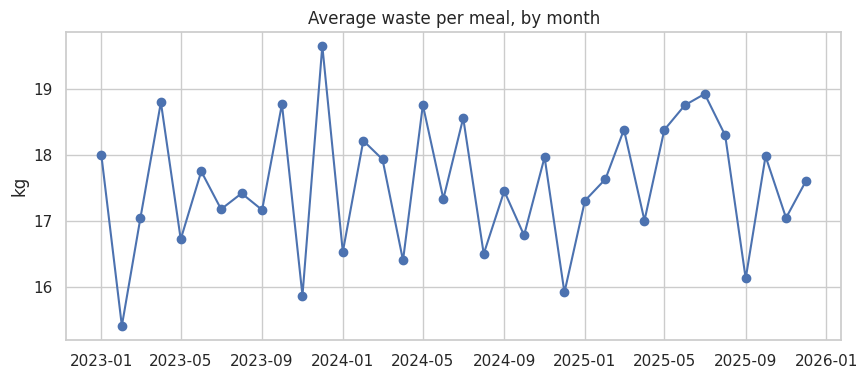

In [38]:
# Waste over time (monthly average)
monthly = df.groupby(df["Date"].dt.to_period("M"))["Food_wasted(kg)"].mean()
plt.figure(figsize=(10,4))
plt.plot(monthly.index.to_timestamp(), monthly.values, marker="o")
plt.title("Average waste per meal, by month")
plt.ylabel("kg")
plt.show()

## 4. Choose input columns (avoid data leakage)

**Data leakage** means giving the model information it would **not have** at prediction time. The model then looks great in testing but is useless in real life.

We want to predict waste **before** the meal, so we only use things known **before** the meal.

| Column | Use it? | Why |
|---|---|---|
| Record_id | No | Just a label |
| Date | No (we use Month instead) | The raw date is not a useful input |
| Actual_MealServed | **No** | Only known after the meal |
| Stockout_flag | **No** | Only known after the meal |
| Prior_similar_wasted_meal(kg) | Yes, with a caution | Fine only if it comes from *earlier* meals (we test this below) |
| All others | Yes | Known when planning |

In [39]:
# Make a Month column from the date (the season may affect waste)
df["Month"] = df["Date"].dt.month

target = "Food_wasted(kg)"
cat_cols = ["Week_day", "Meal_Time", "Menu_category", "Event_type"]
num_cols = ["Holiday_flag", "Planned_Attendance_rate", "Meals_planned", "Expected_meals",
            "Menu_Popularity_score", "Portion_size(g)", "Forecast_temperature(C)",
            "forecast_rainfall(mm)", "Prior_similar_wasted_meal(kg)", "Month"]
features = cat_cols + num_cols

print("Number of input columns:", len(features))
print("Left out on purpose: Record_id, Date, Actual_MealServed, Stockout_flag")

Number of input columns: 14
Left out on purpose: Record_id, Date, Actual_MealServed, Stockout_flag


## 5. Split data by date



In [41]:
df = df.sort_values("Date").reset_index(drop=True)

cutoff_date = df["Date"].iloc[int(0.8 * len(df))]
train = df[df["Date"] < cutoff_date]
test  = df[df["Date"] >= cutoff_date]

X_train, y_train = train[features], train[target]
X_test,  y_test  = test[features],  test[target]

print("Train:", len(train), "meals,", train["Date"].min().date(), "to", train["Date"].max().date())
print("Test: ", len(test),  "meals,", test["Date"].min().date(),  "to", test["Date"].max().date())

Train: 1438 meals, 2023-01-02 to 2025-05-23
Test:  362 meals, 2025-05-25 to 2025-12-30


## 6. Preprocessing


- **Numbers:** fill missing values with the median.
- **Text columns:** convert to 0/1 columns (this is called *one-hot encoding*). For example, Meal_Time becomes Breakfast / Lunch / Dinner columns.

using it for training data only so in order to test on testing data

In [42]:
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
print("Preprocessing ready")

Preprocessing ready


## 7. Baseline models

A **baseline** is a very simple guess. Our real model must beat it, otherwise it is not useful.
- **Baseline 1:** always predict the average waste of the training data.
- **Baseline 2:** predict the average waste for that meal time (Breakfast, Lunch or Dinner).

In [43]:
def evaluate(name, y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    return {"Model": name, "MAE (kg)": round(mae, 2), "RMSE (kg)": round(rmse, 2), "R2": round(r2, 3)}

results = []

# Baseline 1: overall average
base1 = DummyRegressor(strategy="mean").fit(X_train, y_train)
results.append(evaluate("Baseline 1: overall average", y_test, base1.predict(X_test)))

# Baseline 2: average per meal time
meal_avg = train.groupby("Meal_Time")[target].mean()
pred_base2 = test["Meal_Time"].map(meal_avg)
results.append(evaluate("Baseline 2: average per meal time", y_test, pred_base2))

pd.DataFrame(results)

,Model,MAE (kg),RMSE (kg),R2
0,Baseline 1: overall average,7.10,8.91,-0.001
1,Baseline 2: average per meal time,5.94,7.62,0.267


## 8. Train models

We train two models:
- **Linear Regression:** a simple model that draws a "best fit" line. Easy to explain.
- **Random Forest:** many decision trees voting together. It can capture more complex patterns.

In [44]:
# Linear Regression
lin_model = Pipeline([("prep", preprocess), ("model", LinearRegression())])
lin_model.fit(X_train, y_train)
pred_lin = lin_model.predict(X_test)
results.append(evaluate("Linear Regression", y_test, pred_lin))
print("Linear Regression trained")

Linear Regression trained


In [45]:
# Random Forest
rf_model = Pipeline([
    ("prep", preprocess),
    ("model", RandomForestRegressor(n_estimators=200, random_state=42)),
])
rf_model.fit(X_train, y_train)
pred_rf = rf_model.predict(X_test)
results.append(evaluate("Random Forest", y_test, pred_rf))
print("Random Forest trained")

Random Forest trained


## 9. Compare results

**How to read the scores (on the test data):**
- **MAE:** the average mistake in kg. Lower is better.
- **RMSE:** like MAE, but big mistakes count more. Lower is better.
- **R²:** how much of the ups and downs the model explains. 1 is perfect, 0 is no better than guessing the average.

In [46]:
results_df = pd.DataFrame(results)
results_df

,Model,MAE (kg),RMSE (kg),R2
0,Baseline 1: overall average,7.10,8.91,-0.001
1,Baseline 2: average per meal time,5.94,7.62,0.267
2,Linear Regression,4.52,5.81,0.574
3,Random Forest,4.52,5.80,0.575


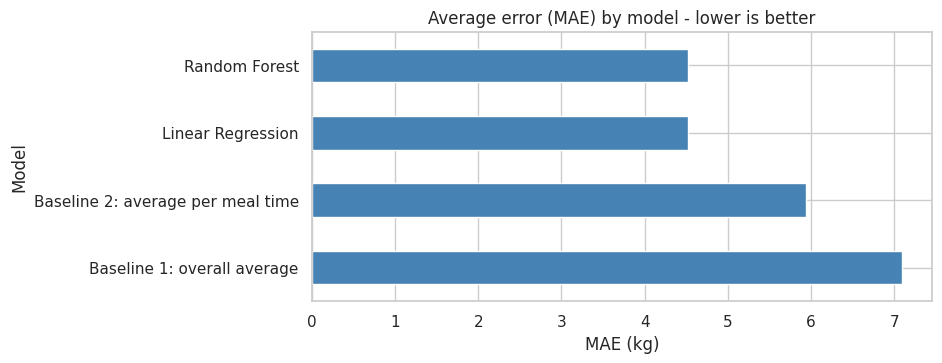

In [47]:
results_df.set_index("Model")["MAE (kg)"].plot(kind="barh", color="steelblue", figsize=(8,3.5))
plt.title("Average error (MAE) by model - lower is better")
plt.xlabel("MAE (kg)")
plt.show()

**Sensitivity check:** the column `Prior_similar_wasted_meal(kg)` could cause leakage if it was built using the same meal's waste. Here we retrain the Random Forest **without** it. If the score falls a lot, our results depend heavily on that one column, and we must mention it in the report.

In [48]:
num_no_prior = [c for c in num_cols if c != "Prior_similar_wasted_meal(kg)"]
prep_no_prior = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_no_prior),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
rf_no_prior = Pipeline([
    ("prep", prep_no_prior),
    ("model", RandomForestRegressor(n_estimators=200, random_state=42)),
])
rf_no_prior.fit(train[cat_cols + num_no_prior], y_train)
pred_no_prior = rf_no_prior.predict(test[cat_cols + num_no_prior])

pd.DataFrame([
    evaluate("Random Forest (with Prior column)", y_test, pred_rf),
    evaluate("Random Forest (without Prior column)", y_test, pred_no_prior),
])

,Model,MAE (kg),RMSE (kg),R2
0,Random Forest (with Prior column),4.52,5.80,0.575
1,Random Forest (without Prior column),4.49,5.77,0.579


## 10. Error analysis

Where does the model do well, and where does it make bigger mistakes?

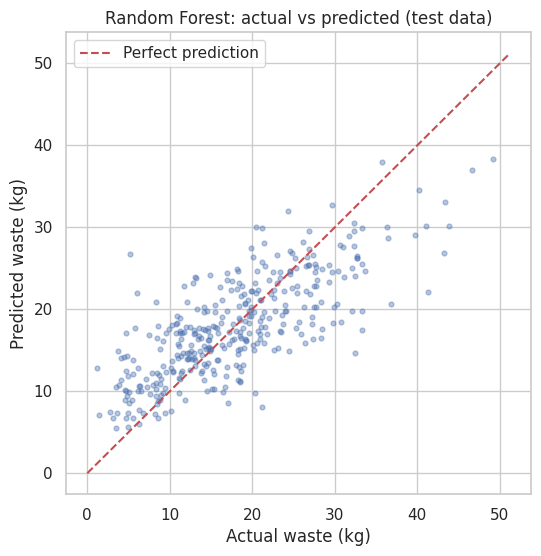

In [49]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, pred_rf, alpha=0.4, s=12)
lim = [0, max(y_test.max(), pred_rf.max()) + 2]
plt.plot(lim, lim, "r--", label="Perfect prediction")
plt.xlabel("Actual waste (kg)")
plt.ylabel("Predicted waste (kg)")
plt.title("Random Forest: actual vs predicted (test data)")
plt.legend()
plt.show()

In [50]:
test_results = test.copy()
test_results["Predicted"] = pred_rf
test_results["Error"] = test_results[target] - test_results["Predicted"]
test_results["Abs_Error"] = test_results["Error"].abs()

print("Average error (MAE) by meal time:")
print(test_results.groupby("Meal_Time")["Abs_Error"].mean().round(2))
print()
print("Average error (MAE) by event type:")
print(test_results.groupby("Event_type")["Abs_Error"].mean().round(2))

Average error (MAE) by meal time:
Meal_Time
Breakfast    3.29
Dinner       4.46
Lunch        5.12
Name: Abs_Error, dtype: float64

Average error (MAE) by event type:
Event_type
College Event    5.26
Exam Period      2.10
Festival         5.19
None             4.59
Sports Event     3.53
Name: Abs_Error, dtype: float64


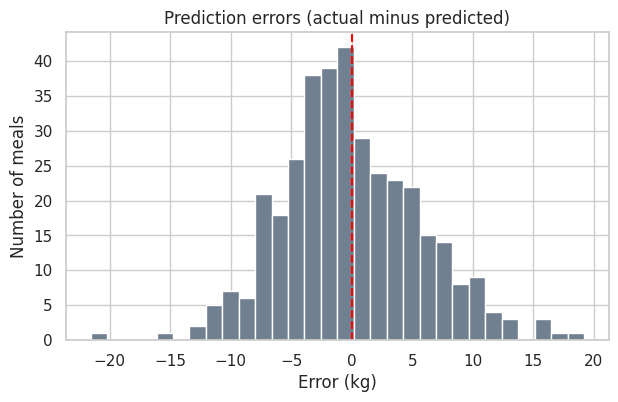

,Date,Meal_Time,Menu_category,Event_type,Food_wasted(kg),Predicted,Abs_Error
1589,2025-08-26,Lunch,South Indian,None,5.19,26.77,21.58
1743,2025-11-26,Dinner,North Indian,None,41.26,22.06,19.20
1688,2025-10-24,Dinner,North Indian,None,32.44,14.63,17.81
1768,2025-12-12,Lunch,Continental,None,43.26,26.82,16.44
1612,2025-09-10,Dinner,Continental,None,36.76,20.65,16.11
1699,2025-11-03,Lunch,Chinese,None,6.03,22.00,15.97
1746,2025-11-27,Dinner,South Indian,None,33.35,17.53,15.82
1551,2025-07-28,Dinner,South Indian,Festival,43.86,30.22,13.64
1457,2025-06-03,Dinner,Chinese,College Event,33.27,19.75,13.52
1608,2025-09-08,Dinner,Continental,None,21.17,8.10,13.07


In [51]:
plt.figure(figsize=(7,4))
plt.hist(test_results["Error"], bins=30, color="slategray", edgecolor="white")
plt.axvline(0, color="red", linestyle="--")
plt.title("Prediction errors (actual minus predicted)")
plt.xlabel("Error (kg)")
plt.ylabel("Number of meals")
plt.show()

# The 10 biggest mistakes
cols_to_show = ["Date", "Meal_Time", "Menu_category", "Event_type", target, "Predicted", "Abs_Error"]
test_results.sort_values("Abs_Error", ascending=False)[cols_to_show].head(10).round(2)

## 11. Feature importance

The Random Forest can tell us which inputs it used most. Be careful:
- It shows what the **model** relied on, not what **causes** waste.
- Related columns (like Meals_planned and Expected_meals) can share the credit.

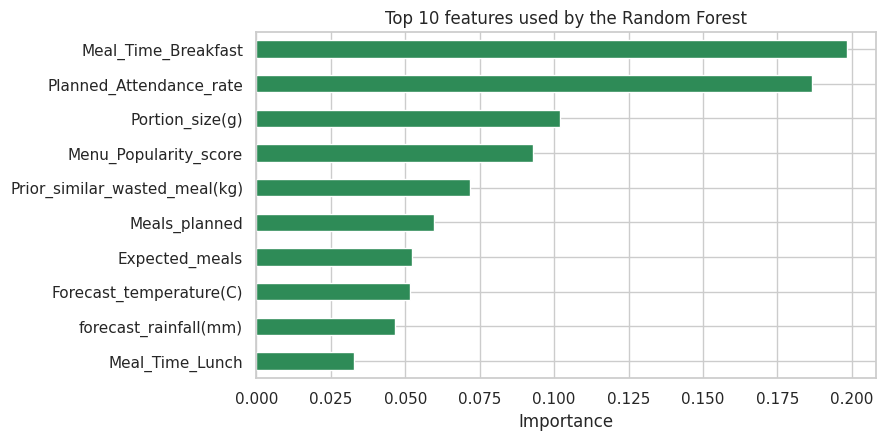

,0
Meal_Time_Breakfast,0.198
Planned_Attendance_rate,0.187
Portion_size(g),0.102
Menu_Popularity_score,0.093
Prior_similar_wasted_meal(kg),0.072
Meals_planned,0.060
Expected_meals,0.052
Forecast_temperature(C),0.052
forecast_rainfall(mm),0.047
Meal_Time_Lunch,0.033


In [52]:
prep_fitted = rf_model.named_steps["prep"]
rf_fitted   = rf_model.named_steps["model"]

names = prep_fitted.get_feature_names_out()
names = [n.split("__")[1] for n in names]   # remove "num__" / "cat__" prefix

importance = pd.Series(rf_fitted.feature_importances_, index=names).sort_values(ascending=False)

importance.head(10).sort_values().plot(kind="barh", figsize=(8,4.5), color="seagreen")
plt.title("Top 10 features used by the Random Forest")
plt.xlabel("Importance")
plt.show()
importance.head(10).round(3)

## 12. Saving the model and trying one prediction

In [54]:
joblib.dump(rf_model, "wasteland_pantry_model.joblib")
print("Saved: wasteland_pantry_model.joblib")

# Load it back and predict for one imaginary meal
loaded_model = joblib.load("wasteland_pantry_model.joblib")

new_meal = pd.DataFrame([{
    "Week_day": "Friday", "Meal_Time": "Lunch", "Menu_category": "North Indian",
    "Event_type": "None", "Holiday_flag": 0, "Planned_Attendance_rate": 0.85,
    "Meals_planned": 450, "Expected_meals": 440, "Menu_Popularity_score": 75,
    "Portion_size(g)": 350, "Forecast_temperature(C)": 28, "forecast_rainfall(mm)": 0.5,
    "Prior_similar_wasted_meal(kg)": 22, "Month": 3,
}])

print("Predicted food waste:", round(loaded_model.predict(new_meal[features])[0], 1), "kg")

Saved: wasteland_pantry_model.joblib
Predicted food waste: 22.7 kg
